### Installing required libraries

In [2]:
# Install required libraries
!pip install seaborn missingno xgboost catboost regex scikit-learn pandas numpy imblearn lightgbm polars


### Importing all libraries 

In [3]:
# Core libraries
import pandas as pd
import numpy as np
import csv
import re

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

# Preprocessing
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.utils import resample

# Model selection
from sklearn.model_selection import (
    train_test_split,
    cross_validate,
    cross_val_score,
    GridSearchCV,
    RandomizedSearchCV
)

# Models
from sklearn.linear_model import LogisticRegression, LinearRegression, SGDClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.svm import LinearSVC
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
import xgboost as xgb

# Metrics
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    classification_report,
    make_scorer
)


### Import additional items as needed...

In [4]:
# Model selection utilities
from sklearn.model_selection import (
    KFold,
    RepeatedStratifiedKFold,
    StratifiedKFold,
    cross_val_score
)

# Preprocessing & pipelines
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PowerTransformer
from sklearn.compose import ColumnTransformer, make_column_transformer
from sklearn.pipeline import Pipeline
from imblearn.pipeline import make_pipeline

# Models & balancing
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from imblearn.over_sampling import SMOTE

# Metrics (only those not already imported in Script 2)
from sklearn.metrics import (
    confusion_matrix,
    balanced_accuracy_score,
    f1_score
)

# Plotly visualization
import plotly
import plotly.express as px
import plotly.graph_objs as go
import plotly.offline as py
from plotly.offline import iplot
from plotly.subplots import make_subplots
import plotly.figure_factory as ff

# Suppress warnings
import warnings
warnings.filterwarnings("ignore")


### Loading CSV data 

In [5]:
diabetes = pd.read_csv('raw/diabetic_data.csv')

# CLEANING AND TRANSFORMING THE DATASET

In [6]:
print(diabetes.columns)

Index(['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight',
       'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
       'time_in_hospital', 'payer_code', 'medical_specialty',
       'num_lab_procedures', 'num_procedures', 'num_medications',
       'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1',
       'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult',
       'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
       'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
       'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
       'tolazamide', 'examide', 'citoglipton', 'insulin',
       'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted'],
      dtype='str')


In [7]:
for g in diabetes['gender'].unique():
    col = f"Gender_{g}"
    diabetes[col] = (diabetes['gender'] == g).astype(int)


In [8]:
#@title AGE ENCODING
# Convert everything to string and strip spaces
diabetes['age'] = diabetes['age'].astype(str).str.strip()

# Mapping age ranges to numeric midpoint values
age_map = {
    '[0-10)': 5,
    '[10-20)': 15,
    '[20-30)': 25,
    '[30-40)': 35,
    '[40-50)': 45,
    '[50-60)': 55,
    '[60-70)': 65,
    '[70-80)': 75,
    '[80-90)': 85,
    '[90-100)': 95
}

# Apply mapping
diabetes['age'] = diabetes['age'].map(age_map)

In [9]:
# Mapping Admission Type ID to interpretable binary categories:
# 1 = Emergency/Urgent/Trauma
# 0 = Elective/Newborn/NotAvailable/NULL/NotMapped

admission_type_binary_map = {
    1: 1,  # Emergency
    2: 1,  # Urgent
    7: 1,  # TraumaCenter

    3: 0,  # Elective
    4: 0,  # Newborn
    5: 0,  # NotAvailable
    6: 0,  # NULL
    8: 0   # NotMapped
}

diabetes["admission_emergency"] = (
    diabetes["admission_type_id"]
    .map(admission_type_binary_map)
    .fillna(0)
    .astype(int)
)


In [10]:
# Binary mapping for discharge disposition:
# 0 = routine / lower‑risk discharge
# 1 = adverse / higher‑risk discharge

discharge_disposition_binary_map = {
    # lower‑risk / routine
    2: 0,   # ShortTermHospital
    11: 0,  # Expired
    12: 0,  # StillPatient
    13: 0,  # HospiceHome   
    14: 0,  # HospiceFacility
    15: 0,  # SwingBed
    19: 0,  # ExpiredHomeMedicaid
    20: 0,  # ExpiredFacilityMedicaid
    21: 0,  # ExpiredUnknownMedicaid
   
    # posible higher‑risk / adverse outcomes
    1: 1,   # Home
    3: 1,   # SNF
    4: 1,   # ICF
    5: 1,   # OtherInpatientCare
    6: 1,   # HomeHealth
    7: 1,   # LeftAMA
    8: 1,   # HomeIVCare
    9: 1,   # AdmittedToThisHospital
    10: 1,  # NeonateToAnotherHospital
    16: 1,  # OutpatientServicesOtherInstitution
    17: 1,  # OutpatientServicesThisInstitution
    18: 1,  # NULL
    22: 1,  # RehabFacility
    23: 1,  # LongTermCareHospital
    24: 1,  # MedicaidNursingFacility
    25: 1,  # NotMapped
    27: 1,  # FederalHealthCareFacility
    28: 1,  # PsychiatricHospital
    29: 1,  # CriticalAccessHospital
    30: 1,   # OtherHealthcareInstitution
    
}

diabetes["DischargeRisk"] = (
    diabetes["discharge_disposition_id"]
        .map(discharge_disposition_binary_map)
        .fillna(0)
        .astype(int)
)


In [11]:
def icd_to_chapter(code):
    # Handle missing or non-numeric codes
    try:
        code = float(code)
    except:
        return "Unknown"

    if 1 <= code <= 139:
        return "Infectious and Parasitic Diseases"
    elif 140 <= code <= 239:
        return "Neoplasms"
    elif 240 <= code <= 279:
        return "Endocrine/Metabolic"
    elif 280 <= code <= 289:
        return "Blood Diseases"
    elif 290 <= code <= 319:
        return "Mental Disorders"
    elif 320 <= code <= 389:
        return "Nervous System"
    elif 390 <= code <= 459:
        return "Circulatory System"
    elif 460 <= code <= 519:
        return "Respiratory System"
    elif 520 <= code <= 579:
        return "Digestive System"
    elif 580 <= code <= 629:
        return "Genitourinary System"
    elif 630 <= code <= 679:
        return "Pregnancy/Childbirth"
    elif 680 <= code <= 709:
        return "Skin/Subcutaneous"
    elif 710 <= code <= 739:
        return "Musculoskeletal"
    elif 740 <= code <= 759:
        return "Congenital Anomalies"
    elif 760 <= code <= 779:
        return "Perinatal Conditions"
    elif 780 <= code <= 799:
        return "Symptoms/Ill-defined"
    elif 800 <= code <= 999:
        return "Injury/Poisoning"
    elif code >= 1000:
        return "Unknown"
    else:
        return "Unknown"


In [12]:
for col in ["diag_1", "diag_2", "diag_3"]:
    diabetes[col + "_chapter"] = diabetes[col].apply(icd_to_chapter)


In [14]:
# ============================================================
# Binary mapping for ICD diagnosis chapters
# ============================================================
diag_binary_map = {
    "Endocrine/Metabolic": 1,
    "Circulatory System": 1,
    "Respiratory System": 1,
    "Neoplasms": 1,
    "Infectious and Parasitic Diseases": 1,
    "Injury/Poisoning": 1,
    "Genitourinary System": 1,
    "Nervous System": 1,
    "Blood Diseases": 1,
    "Mental Disorders": 1,

    "Symptoms/Ill-defined": 0,
    "Skin/Subcutaneous": 0,
    "Musculoskeletal": 0,
    "Digestive System": 0,
    "Pregnancy/Childbirth": 0,
    "Congenital Anomalies": 0,
    "V-Codes": 0,
    "E-Codes": 0,
    "Unknown": 0
}

for col in ["diag_1_chapter", "diag_2_chapter", "diag_3_chapter"]:
    diabetes[col] = (
        diabetes[col]
            .map(diag_binary_map)
            .fillna(0)
            .astype(int)
    )


In [15]:
#@title DIABEST MEDICATION ENCODING
# replacing No with 0 and Yes with 1 for if the patient has diabetic medications or not
diabetes['diabetesMed'] = diabetes['diabetesMed'].apply(
    lambda x: 1 if str(x).strip().lower() == "yes" else 0
)

In [16]:
#@title READMITTED ENCODING
# Created indicator column for readmission within 30 days
# lessthan30 = 1 if readmitted is "<30", else 0

diabetes['lessthan30'] = (diabetes['readmitted'] == '<30').astype(int)

In [17]:
#@title RACE ENCODING
# Replace '?' with 'Unknown'
diabetes['race'] = diabetes['race'].replace('?', 'Unknown')

# Create binary columns for each race category
for race in diabetes['race'].unique():
    col_name = f"Race_{race}"
    diabetes[col_name] = (diabetes['race'] == race).astype(int)


In [18]:
diabetes.columns

Index(['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight',
       'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
       'time_in_hospital', 'payer_code', 'medical_specialty',
       'num_lab_procedures', 'num_procedures', 'num_medications',
       'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1',
       'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult',
       'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
       'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
       'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
       'tolazamide', 'examide', 'citoglipton', 'insulin',
       'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted',
       'Gender_Female', 'Gender_Male', 'Gender_Unknown/Invalid',
       'admission_emergency

In [19]:
import random

# -----------------------------
# 1. Conversion functions
# -----------------------------

def convert_weight(value):
    if pd.isna(value) or value == "None":
        return None
    
    value = str(value)

    if value.startswith('>'):
        return random.randint(201, 250)

    if '-' in value:
        clean = value.replace('(', '').replace(')', '')
        low, high = clean.split('-')
        return int(high)

    return None


def convert_glucose(value):
    if pd.isna(value) or value == "None":
        return None
    
    value = str(value)

    if value.startswith('>'):
        threshold = int(value[1:])
        return random.randint(threshold + 1, threshold + 50)

    if value == "Norm":
        return random.randint(70, 99)

    return None


def convert_a1c(value):
    if pd.isna(value) or value == "None":
        return None
    
    value = str(value)

    if value.startswith('>'):
        threshold = float(value[1:])
        return round(random.uniform(threshold + 0.1, threshold + 1.0), 1)

    if value == "Norm":
        return round(random.uniform(4.0, 5.6), 1)

    return None


# -----------------------------
# 2. Apply conversions
# -----------------------------

diabetes['weight_num'] = diabetes['weight'].apply(convert_weight)
diabetes['max_glu_serum_num'] = diabetes['max_glu_serum'].apply(convert_glucose)
diabetes['A1Cresult_num'] = diabetes['A1Cresult'].apply(convert_a1c)


# -----------------------------
# 3. RANDOM IMPUTATION for NaN
# -----------------------------

# Random weight between 25 and 250
diabetes['weight_num'] = diabetes['weight_num'].apply(
    lambda x: x if not pd.isna(x) else random.randint(25, 250)
)

# Random glucose between 70 and 350
diabetes['max_glu_serum_num'] = diabetes['max_glu_serum_num'].apply(
    lambda x: x if not pd.isna(x) else random.randint(70, 350)
)

# Random A1C between 4.0 and 10.0
diabetes['A1Cresult_num'] = diabetes['A1Cresult_num'].apply(
    lambda x: x if not pd.isna(x) else round(random.uniform(4.0, 10.0), 1)
)


# -----------------------------
# 4. Verify no missing values
# -----------------------------

print(diabetes[['weight_num','max_glu_serum_num','A1Cresult_num']].isna().sum())


weight_num           0
max_glu_serum_num    0
A1Cresult_num        0
dtype: int64


In [20]:
#@title drop 1 intial columns
# Dropping unnecessary columns due to high missing values and low relevance
cleandiabetes = diabetes.drop([
    'encounter_id', 'patient_nbr', 'race', 'gender', 'weight', 'max_glu_serum', 'A1Cresult',
       'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
       'payer_code', 'medical_specialty', 'diag_1',
       'diag_2', 'diag_3', 
       'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
       'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
       'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
       'tolazamide', 'examide', 'citoglipton', 'insulin',
       'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'readmitted'
], axis=1)

In [ ]:
print(cleandiabetes.columns)

In [21]:
numerical = [ 'age' , 'time_in_hospital',
    'num_lab_procedures',
    'num_procedures',
    'num_medications',
    'number_emergency',
    'number_outpatient',
    'number_inpatient',
    'number_diagnoses','weight_num', 'max_glu_serum_num', 'A1Cresult_num' ]

### MISSING DATA

In [22]:
def missing(df):
    missing_number = df.isnull().sum().sort_values(ascending=False)
    missing_percent = (df.isnull().sum() / df.isnull().count()).sort_values(ascending=False)
    missing_values = pd.concat([missing_number, missing_percent], axis=1,
                               keys=['Missing_Number', 'Missing_Percent'])
    return missing_values

In [23]:
print("Missing Data in Sub1:")
display(missing(cleandiabetes))



Missing Data in Sub1:


,Missing_Number,Missing_Percent
age,0,0.0
time_in_hospital,0,0.0
num_lab_procedures,0,0.0
num_procedures,0,0.0
num_medications,0,0.0
number_outpatient,0,0.0
number_emergency,0,0.0
number_inpatient,0,0.0
number_diagnoses,0,0.0
diabetesMed,0,0.0


### CORRELATION

In [24]:
#@title Correlation Matrices
print("Correlation Matrix for Sub1")
display(cleandiabetes[numerical].corr())

Correlation Matrix for Sub1


,age,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_emergency,number_outpatient,number_inpatient,number_diagnoses,weight_num,max_glu_serum_num,A1Cresult_num
age,1.000000,0.107515,0.020770,-0.030104,0.041847,-0.087291,0.023724,-0.042861,0.242597,-0.007005,-0.010316,-0.035992
time_in_hospital,0.107515,1.000000,0.318450,0.191472,0.466135,-0.009681,-0.008916,0.073623,0.220186,-0.004180,0.010387,0.001233
num_lab_procedures,0.020770,0.318450,1.000000,0.058066,0.268161,-0.002279,-0.007602,0.039231,0.152773,-0.012456,0.025681,0.014393
num_procedures,-0.030104,0.191472,0.058066,1.000000,0.385767,-0.038179,-0.024819,-0.066236,0.073734,-0.006734,-0.002105,-0.001524
num_medications,0.041847,0.466135,0.268161,0.385767,1.000000,0.013180,0.045197,0.064194,0.261526,0.004736,0.009623,-0.003892
number_emergency,-0.087291,-0.009681,-0.002279,-0.038179,0.013180,1.000000,0.091459,0.266559,0.055539,0.008602,0.003110,0.000572
number_outpatient,0.023724,-0.008916,-0.007602,-0.024819,0.045197,0.091459,1.000000,0.107338,0.094152,-0.006334,-0.011903,0.004093
number_inpatient,-0.042861,0.073623,0.039231,-0.066236,0.064194,0.266559,0.107338,1.000000,0.104710,0.000654,0.007065,0.001212
number_diagnoses,0.242597,0.220186,0.152773,0.073734,0.261526,0.055539,0.094152,0.104710,1.000000,-0.002538,0.005698,-0.018972
weight_num,-0.007005,-0.004180,-0.012456,-0.006734,0.004736,0.008602,-0.006334,0.000654,-0.002538,1.000000,0.001110,0.007464


In [25]:
print("Correlation for lessthan30 grouped by readmit_less_30")
display(cleandiabetes.groupby('lessthan30')[numerical].corr())


Correlation for lessthan30 grouped by readmit_less_30


age  time_in_hospital  num_lab_procedures  \
lessthan30                                                                      
0          age                 1.000000          0.110387            0.023671   
           time_in_hospital    0.110387          1.000000            0.317989   
           num_lab_procedures  0.023671          0.317989            1.000000   
           num_procedures     -0.030476          0.184408            0.052895   
           num_medications     0.045641          0.463444            0.263560   
           number_emergency   -0.073727         -0.003926            0.004755   
           number_outpatient   0.025838         -0.008024           -0.009675   
           number_inpatient   -0.012445          0.081368            0.044145   
           number_diagnoses    0.250573          0.222780            0.153492   
           weight_num         -0.008760         -0.003882           -0.013497   
           max_glu_serum_num  -0.009754          0.010322            0.026150   
           A1Cresult_num      -0.036752         -0.001184            0.015267   
1          age                 1.000000          0.078964           -0.006361   
           time_in_hospital    0.078964          1.000000            0.317655   
           num_lab_procedures -0.006361          0.317655            1.000000   
           num_procedures     -0.025012          0.256572            0.104734   
           num_medications     0.005392          0.479381            0.300945   
           number_emergency   -0.171721         -0.054951           -0.046064   
           number_outpatient   0.004394         -0.022948            0.005296   
           number_inpatient   -0.209974          0.011970            0.004974   
           number_diagnoses    0.167476          0.182704            0.138825   
           weight_num          0.006206         -0.008538           -0.005014   
           max_glu_serum_num  -0.014603          0.011558            0.022209   
           A1Cresult_num      -0.030848          0.017915            0.006298   

                               num_procedures  num_medications  \
lessthan30                                                       
0          age                      -0.030476         0.045641   
           time_in_hospital          0.184408         0.463444   
           num_lab_procedures        0.052895         0.263560   
           num_procedures            1.000000         0.385410   
           num_medications           0.385410         1.000000   
           number_emergency         -0.036945         0.017058   
           number_outpatient        -0.023123         0.044063   
           number_inpatient         -0.063114         0.066989   
           number_diagnoses          0.071852         0.261229   
           weight_num               -0.005883         0.005356   
           max_glu_serum_num        -0.000548         0.008653   
           A1Cresult_num            -0.002687        -0.004213   
1          age                      -0.025012         0.005392   
           time_in_hospital          0.256572         0.479381   
           num_lab_procedures        0.104734         0.300945   
           num_procedures            1.000000         0.396435   
           num_medications           0.396435         1.000000   
           number_emergency         -0.044692        -0.019015   
           number_outpatient        -0.036554         0.048016   
           number_inpatient         -0.084559         0.028102   
           number_diagnoses          0.098215         0.251496   
           weight_num               -0.013217        -0.001921   
           max_glu_serum_num        -0.015208         0.017917   
           A1Cresult_num             0.008780        -0.003289   

                               number_emergency  number_outpatient  \
lessthan30                                                           
0          age                        -0.073727           0.025838   
  

In [26]:
#@title Reusable Correlation Heatmaps
def plot_corr_heatmap(df, numerical, title):
    """
    Plots a lower‑triangle correlation heatmap for a given dataframe.
    """
    corr_matrix = df[numerical].corr()

    # Mask upper triangle
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

    plt.figure(figsize=(10, 8))
    sns.heatmap(
        corr_matrix,
        annot=True,
        cmap='coolwarm',
        center=0,
        square=True,
        linewidths=0.5,
        fmt='.2f',
        mask=mask
    )

    plt.title(title, fontsize=14)
    plt.tight_layout()
    plt.show()


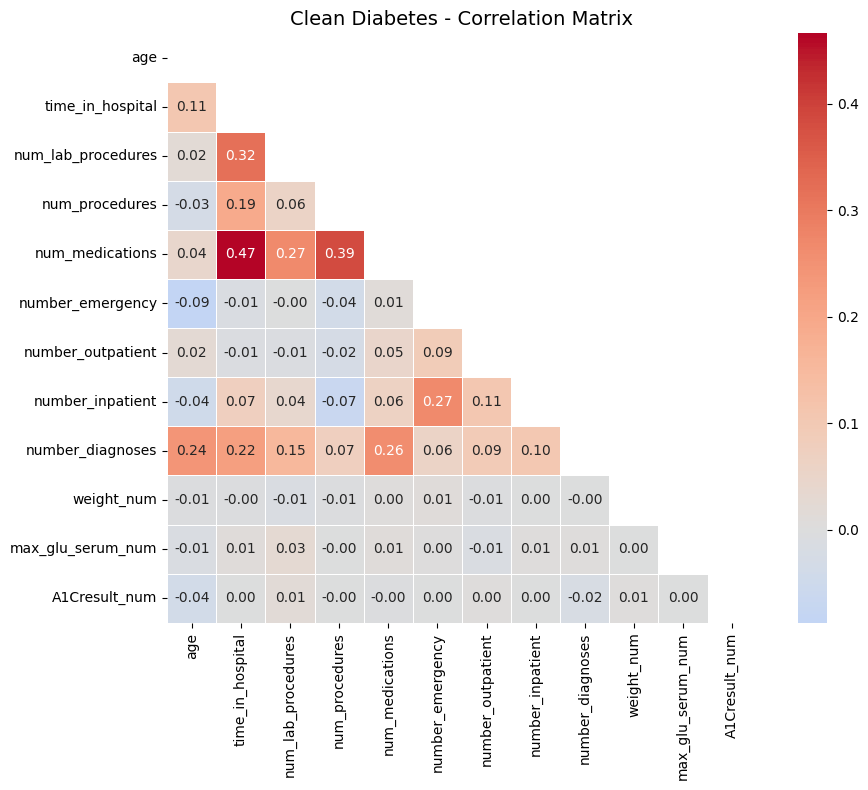

In [27]:
plot_corr_heatmap(cleandiabetes, numerical, "Clean Diabetes - Correlation Matrix")


## Breaking the data up into Train & Test

In [28]:
#@title Setting Up Data for Modeling 
#Uses the cleandiabetes dataset for modeling.
DataTesting = cleandiabetes.copy() #change it to sub2 or Sub3 to test each dataset

In [29]:
# Step 1: Split cleandiabetes into Train (70%) and Temp (30%)
train_df, temp_df = train_test_split(
    DataTesting,
    test_size=0.30,        # 30% goes to temp (valid + test)
    random_state=42,       # ensures reproducibility
    shuffle=True           # shuffles before splitting
)


# Step 2: Split Temp into Validation (15%) and Test (15%)
valid_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,        # half of temp = 15% of total
    random_state=42,
    shuffle=True
)

# Step 3: Reset indexes for cleanliness
train_df = train_df.reset_index(drop=True)
valid_df = valid_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)


# Step 4: Just Making Sure Check
print("Train size:", len(train_df))
print("Validation size:", len(valid_df))
print("Test size:", len(test_df))
print("Total:", len(train_df) + len(valid_df) + len(test_df))


Train size: 71236
Validation size: 15265
Test size: 15265
Total: 101766


In [30]:
DataTesting.lessthan30.value_counts()

lessthan30
0    90409
1    11357
Name: count, dtype: int64

In [31]:
train_df.lessthan30.value_counts()

lessthan30
0    63304
1     7932
Name: count, dtype: int64

In [32]:
valid_df.lessthan30.value_counts()

lessthan30
0    13500
1     1765
Name: count, dtype: int64

In [33]:
test_df.lessthan30.value_counts()

lessthan30
0    13605
1     1660
Name: count, dtype: int64

## Ways to Fix/Treat the Imbalance in the Data
Imbalance in the data means that one of the classes in the data is too less as compared to the others. Typically, it is better to balance the data in some way to give the positives more weight. There are 3 strategies that are typically utilized:

#### 1. RANDOM OVERSAMPLING: 
This technique involves randomly duplicating examples from the minority class in the training dataset. 
This can help balance the class distribution but may lead to overfitting since it replicates existing data points.

In [34]:
def balance_random_oversample(df, target='readmit_less_30', random_state=42):
    df_pos = df[df[target] == 1]
    df_neg = df[df[target] == 0]

    df_pos_over = resample(
        df_pos,
        replace=True,
        n_samples=len(df_neg),
        random_state=random_state
    )

    df_bal = (
        pd.concat([df_neg, df_pos_over])
        .sample(frac=1, random_state=random_state)
        .reset_index(drop=True)
    )

    return df_bal

#### 2. SMOTE 
(Synthetic Minority Over-sampling Technique): SMOTE generates synthetic examples of the minority class by interpolating between existing minority class examples. 
This can help create a more balanced dataset without simply duplicating existing data points, which may reduce the risk of overfitting compared to random oversampling.

In [35]:
def balance_smote(df, target='readmit_less_30', random_state=42):
    X = df.drop(columns=[target])
    y = df[target]

    sm = SMOTE(random_state=random_state)
    X_res, y_res = sm.fit_resample(X, y)

    df_bal = pd.concat(
        [pd.DataFrame(X_res, columns=X.columns),
         pd.Series(y_res, name=target)],
        axis=1
    )

    return df_bal

#### 3. RANDOM UNDERSAMPLING
Random Undersampling reduces the size of the majority class by randomly removing samples until it matches the minority class count. This creates a balanced dataset without generating synthetic data.

In [36]:
def balance_random_undersample(df, target='readmit_less_30', random_state=42):
    df_pos = df[df[target] == 1]
    df_neg = df[df[target] == 0]

    df_neg_under = df_neg.sample(
        n=len(df_pos),
        random_state=random_state
    )

    df_bal = (
        pd.concat([df_pos, df_neg_under])
        .sample(frac=1, random_state=random_state)
        .reset_index(drop=True)
    )

    return df_bal

#### 4. SMOTEENN


In [37]:
from imblearn.combine import SMOTEENN
from imblearn.over_sampling import SMOTE

def apply_smoteenn(X, y, k_neighbors=5, random_state=42):
    """
    Apply SMOTEENN hybrid resampling:
    - SMOTE oversamples the minority class
    - ENN removes noisy majority samples

    Returns:
        X_resampled, y_resampled
    """
    smote = SMOTE(k_neighbors=k_neighbors, random_state=random_state)
    smote_enn = SMOTEENN(smote=smote, random_state=random_state)

    X_resampled, y_resampled = smote_enn.fit_resample(X, y)
    return X_resampled, y_resampled

#### 5. SMOTETOMEK

In [38]:
from imblearn.combine import SMOTETomek

def apply_smotetomek(X, y, k_neighbors=5, random_state=42):
    """
    Apply SMOTETomek hybrid resampling:
    - SMOTE oversamples the minority class
    - Tomek Links remove borderline/noisy majority samples

    Returns:
        X_resampled, y_resampled
    """
    smote = SMOTE(k_neighbors=k_neighbors, random_state=random_state)
    smote_tomek = SMOTETomek(smote=smote, random_state=random_state)

    X_resampled, y_resampled = smote_tomek.fit_resample(X, y)
    return X_resampled, y_resampled


#### Prevalence Caculation Function

In [39]:
def calc_prevalence(y_actual):
    """
    Calculate the prevalence (ratio of positive class = 1)
    in a binary target array or Series.
    """
    y_actual = pd.Series(y_actual)
    return y_actual.mean()

<h2 style="color:#e63946;">CHANGE THE IMBALANCE TECHNIQUE HERE</h2>
“Remove the # to activate a specific technique."


In [40]:
# 1. Split train_df into X and y
X_train = train_df.drop(columns=["lessthan30"])
y_train = train_df["lessthan30"]

# 2. Apply SMOTEENN
X_bal, y_bal = apply_smoteenn(X_train, y_train)

# 3. Combine back into a single DataFrame (optional)
train_balanced = X_bal.copy()
train_balanced["lessthan30"] = y_bal

# 4. Check prevalence
print(
    "Train balanced prevalence (n = %d): %.3f" %
    (len(train_balanced), calc_prevalence(train_balanced['lessthan30']))
)


Train balanced prevalence (n = 95371): 0.636


In [42]:
train_balanced.lessthan30.value_counts()

lessthan30
1    60642
0    34729
Name: count, dtype: int64

In [43]:
X_train = train_balanced.drop('lessthan30',axis=1)

y_train = train_balanced['lessthan30']

X_valid = valid_df.drop('lessthan30',axis=1)

y_valid = valid_df['lessthan30']

X_test = test_df.drop('lessthan30',axis=1)

y_test = test_df['lessthan30']

<h2 style="color:#e63946;">CHANGE THE SETS HERE FOR SCALER</h2>

In [44]:
scale_cols = numerical
# -----------------------------------------
# 1. Fit the scaler on TRAINING data only
# -----------------------------------------
scaler = StandardScaler()
X_train[scale_cols] = scaler.fit_transform(X_train[scale_cols])

# -----------------------------------------
# 2. Transform VALIDATION and TEST sets
# -----------------------------------------
X_valid[scale_cols] = scaler.transform(X_valid[scale_cols])
X_test[scale_cols]  = scaler.transform(X_test[scale_cols])


In [45]:
X_train.head()

,age,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,diabetesMed,...,diag_3_chapter,Race_Caucasian,Race_AfricanAmerican,Race_Unknown,Race_Other,Race_Asian,Race_Hispanic,weight_num,max_glu_serum_num,A1Cresult_num
0,-0.075359,-0.103760,-0.236061,-0.731724,-0.661439,-0.275901,-0.211161,-0.540975,-1.358415,0,...,0,1,0,0,0,0,0,0.675216,1.200319,-0.094783
1,-0.075359,1.355192,0.079042,-0.731724,1.051914,-0.275901,0.879536,2.328510,0.915160,1,...,0,1,0,0,0,0,0,-0.285094,-0.463432,0.287768
2,-0.075359,2.814144,0.394144,-0.731724,-0.529643,-0.275901,-0.211161,-0.540975,-0.221628,1,...,0,1,0,0,0,0,0,-1.260892,-0.487545,-1.624986
3,0.572146,-0.468498,-1.286402,-0.731724,0.920118,-0.275901,1.970233,0.893767,0.346766,1,...,0,1,0,0,0,0,0,-1.369314,0.296106,1.307903
4,-0.075359,-0.103760,-1.286402,3.299385,-0.134253,-0.275901,-0.211161,-0.540975,0.346766,1,...,0,1,0,0,0,0,0,-0.362538,-0.716612,-1.114919


In [46]:
X_train.head().T

,0,1,2,3,4
age,-0.075359,-0.075359,-0.075359,0.572146,-0.075359
time_in_hospital,-0.103760,1.355192,2.814144,-0.468498,-0.103760
num_lab_procedures,-0.236061,0.079042,0.394144,-1.286402,-1.286402
num_procedures,-0.731724,-0.731724,-0.731724,-0.731724,3.299385
num_medications,-0.661439,1.051914,-0.529643,0.920118,-0.134253
number_outpatient,-0.275901,-0.275901,-0.275901,-0.275901,-0.275901
number_emergency,-0.211161,0.879536,-0.211161,1.970233,-0.211161
number_inpatient,-0.540975,2.328510,-0.540975,0.893767,-0.540975
number_diagnoses,-1.358415,0.915160,-0.221628,0.346766,0.346766
diabetesMed,0.000000,1.000000,1.000000,1.000000,1.000000


## Creating and Understanding Models

In [47]:
def calc_specificity(y_actual, y_pred, thresh):
    # calculates specificity
    return sum((y_pred < thresh) & (y_actual == 0)) /sum(y_actual ==0)

def print_report(y_actual, y_pred, thresh = 0.5):
    
    '''
    This function calculates all the metrics to asses the machine learning models.
    
    Params:
    1. y_actual: The actual values for the target variable.
    2. y_pred: The predicted values for the target variable.
    3. thresh: The threshold for the probability to be considered as a positive class. Default value 0.5
    
    Return:
    1. AUC - ROC Curve
    2. Accuracy
    3. Recall
    4. Precision
    5. Specificity
    '''
    
    auc = roc_auc_score(y_actual, y_pred)
    accuracy = accuracy_score(y_actual, (y_pred > thresh))
    recall = recall_score(y_actual, (y_pred > thresh))
    precision = precision_score(y_actual, (y_pred > thresh))
    specificity = calc_specificity(y_actual, y_pred, thresh)
    print('AUC:%.3f'%auc)
    print('accuracy:%.3f'%accuracy)
    print('recall:%.3f'%recall)
    print('precision:%.3f'%precision)
    print('specificity:%.3f'%specificity)
    print('prevalence:%.3f'%calc_prevalence(y_actual))
    print(' ')
    return auc, accuracy, recall, precision, specificity

### Linear Regression

In [48]:
# disable truncation so NumPy prints the entire array
np.set_printoptions(threshold=np.inf)

lnr = LinearRegression()
lnr.fit(X_train, y_train)

y_valid_preds = lnr.predict(X_valid)

In [49]:
print(y_valid_preds)

[ 5.49850243e-01  4.43323032e-01  3.86340413e-01  1.55068162e-01
  4.00329671e-01  5.25680196e-01  4.71033152e-01  4.70864609e-01
  3.18192853e-01  4.51328624e-01  5.17871184e-01  2.80415214e-01
  3.86458637e-01  4.75172778e-01  4.66585323e-01  3.05512995e-01
  4.61689823e-01  3.58442816e-01  4.48332115e-01  4.66280440e-01
  4.60091589e-01  6.37758355e-01  4.94320112e-01  4.95185267e-01
  3.86102371e-01  5.87801373e-01  3.25432185e-01  5.56776872e-01
  5.82698776e-01  6.01519279e-01  5.39025782e-01  2.75074922e-01
  3.95350270e-01  2.08861399e-01  4.78097687e-01  6.88972937e-01
  4.07356238e-01  6.70414680e-01  4.24203948e-01  6.45973765e-01
  4.53075899e-01  5.96157301e-01  4.78427774e-01  1.69322484e-01
  4.12503473e-01  4.32524838e-01  5.01079224e-01  4.59918604e-01
  5.00087945e-01  4.70922509e-01  4.02211611e-01  7.30155960e-01
  4.89306523e-01  5.07263833e-01  2.88169216e-01  5.44356364e-01
  2.65071309e-02  1.40387882e-01  1.61766509e-01  5.77920209e-01
  4.71166268e-01  5.31054

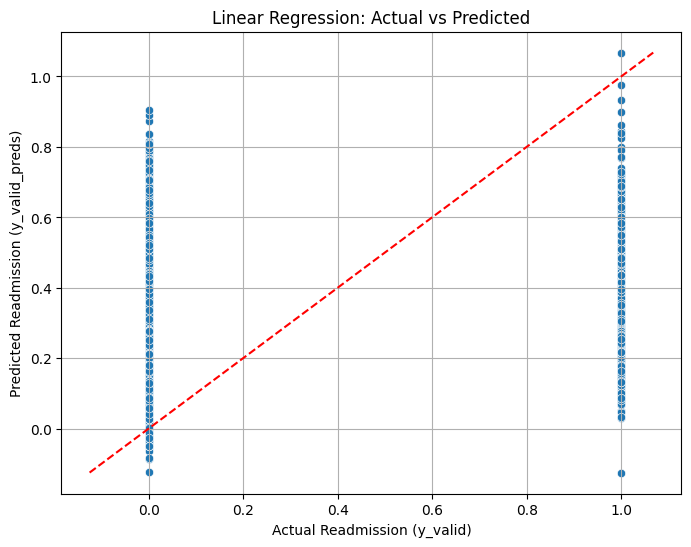

In [50]:
# Create a scatter plot of Actual vs Predicted
plt.figure(figsize=(8,6))
sns.scatterplot(x=y_valid, y=y_valid_preds)

# Add a 45-degree reference line
min_val = min(y_valid.min(), y_valid_preds.min())
max_val = max(y_valid.max(), y_valid_preds.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--')

plt.xlabel("Actual Readmission (y_valid)")
plt.ylabel("Predicted Readmission (y_valid_preds)")
plt.title("Linear Regression: Actual vs Predicted")
plt.grid(True)
plt.show()


### Logistic Regression

In [51]:
lr=LogisticRegression(random_state = 42, solver = 'newton-cg', max_iter = 200)
lr.fit(X_train, y_train)

y_valid_preds = lr.predict_proba(X_valid)[:,1]

print('Metrics for Validation data:')

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,y_valid_preds, 0.5)

Metrics for Validation data:
AUC:0.567
accuracy:0.733
recall:0.293
precision:0.155
specificity:0.790
prevalence:0.116
 


### KNN Model

In [52]:
knn = KNeighborsClassifier(n_neighbors = 100)
knn.fit(X_train, y_train)

knn_preds = knn.predict_proba(X_valid)[:,1]

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,knn_preds, 0.5)

AUC:0.587
accuracy:0.404
recall:0.747
precision:0.132
specificity:0.332
prevalence:0.116
 


### Stochastic Gradient Descent Model

In [53]:
sgdc = SGDClassifier(loss='log_loss', alpha=0.1, random_state=42)
sgdc.fit(X_train, y_train)

sgd_preds = sgdc.predict_proba(X_valid)[:, 1]

print('Stochastic Gradient Descent')
print('Validation:')
sgdc_valid_auc, sgdc_valid_accuracy, sgdc_valid_recall, \
sgdc_valid_precision, sgdc_valid_specificity = print_report(y_valid, sgd_preds, 0.5)

Stochastic Gradient Descent
Validation:
AUC:0.581
accuracy:0.221
recall:0.909
precision:0.120
specificity:0.130
prevalence:0.116
 


### Decision Tree

In [54]:
dc_clf = DecisionTreeClassifier(random_state=42, max_depth = 10)
dc_clf.fit(X_train, y_train)

dc_preds_proba = dc_clf.predict_proba(X_valid)[:,1]
dc_preds = dc_clf.predict(X_valid)

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,dc_preds_proba, 0.5)

AUC:0.556
accuracy:0.791
recall:0.197
precision:0.164
specificity:0.868
prevalence:0.116
 


### Random Forest

In [55]:
rf_clf = RandomForestClassifier(random_state=111, max_depth = 6)

rf_clf.fit(X_train, y_train)

rf_preds = rf_clf.predict(X_valid)
rf_preds_proba = rf_clf.predict_proba(X_valid)[:, 1]

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,rf_preds_proba, 0.5)

AUC:0.560
accuracy:0.468
recall:0.640
precision:0.131
specificity:0.446
prevalence:0.116
 


### Linear SVC

In [56]:
lsvc_clf = LinearSVC(random_state=111)
lsvc_clf.fit(X_train, y_train)

lsvc_preds = lsvc_clf.decision_function(X_valid)

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,lsvc_preds, 0.5)

AUC:0.567
accuracy:0.881
recall:0.024
precision:0.305
specificity:0.993
prevalence:0.116
 


### Gradient Boosting Model

In [57]:
gb_clf = GradientBoostingClassifier(n_estimators = 100, criterion='friedman_mse', learning_rate = 1.0, max_depth = 3,\
                                    random_state = 111)

gb_clf.fit(X_train, y_train)
gb_preds = gb_clf.predict(X_valid)
gb_preds_proba = gb_clf.predict_proba(X_valid)[:, 1]

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,gb_preds_proba, 0.5)

AUC:0.582
accuracy:0.826
recall:0.152
precision:0.189
specificity:0.915
prevalence:0.116
 


### XGB Model

In [58]:
xgb_clf = xgb.XGBClassifier(max_depth=3, learning_rate = 1.0, use_label_encoder = False,\
                            eval_metric = 'logloss')
xgb_clf.fit(X_train, y_train)

xgb_preds = xgb_clf.predict(X_valid)
xgb_preds_proba = xgb_clf.predict_proba(X_valid)[:, 1]

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,xgb_preds_proba, 0.5)

AUC:0.589
accuracy:0.838
recall:0.133
precision:0.198
specificity:0.930
prevalence:0.116
 


### Catboost Model

In [59]:
catb=CatBoostClassifier(iterations=200, depth=3, learning_rate=1.0, random_state = 111)
catb.fit(X_train, y_train)
catb_preds = catb.predict_proba(X_valid)[:, 1]

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,catb_preds, 0.5)

0:	learn: 0.4938799	total: 156ms	remaining: 31.1s
1:	learn: 0.4534439	total: 162ms	remaining: 16.1s
2:	learn: 0.4280665	total: 168ms	remaining: 11s
3:	learn: 0.4156008	total: 173ms	remaining: 8.48s
4:	learn: 0.4073021	total: 182ms	remaining: 7.09s
5:	learn: 0.3982281	total: 190ms	remaining: 6.16s
6:	learn: 0.3935028	total: 196ms	remaining: 5.42s
7:	learn: 0.3870650	total: 202ms	remaining: 4.85s
8:	learn: 0.3826935	total: 207ms	remaining: 4.4s
9:	learn: 0.3690853	total: 215ms	remaining: 4.08s
10:	learn: 0.3664615	total: 225ms	remaining: 3.87s
11:	learn: 0.3647368	total: 232ms	remaining: 3.63s
12:	learn: 0.3509478	total: 238ms	remaining: 3.42s
13:	learn: 0.3399919	total: 246ms	remaining: 3.26s
14:	learn: 0.3387488	total: 253ms	remaining: 3.11s
15:	learn: 0.3309305	total: 260ms	remaining: 2.99s
16:	learn: 0.3279657	total: 266ms	remaining: 2.86s
17:	learn: 0.3266087	total: 270ms	remaining: 2.73s
18:	learn: 0.3254148	total: 276ms	remaining: 2.62s
19:	learn: 0.3231225	total: 281ms	remaining:

## Hyper Parameter Tuning

### Decision Tree

In [60]:
# Decision Tree - Hyperparameter Tuning
recall_scoring = make_scorer(recall_score)

dc_grid = {'max_features':['auto','sqrt'], # maximum number of features to use at each split
           'max_depth':range(1,11,1), # maximum depth of the tree
           'min_samples_split':range(2,10,2), # minimum number of samples to split a node
           'min_samples_leaf': range(1, 11, 2), ###  -->> Added a critical param
           'criterion':['gini','entropy']} # criterion for evaluating a split

dc_random = RandomizedSearchCV(estimator = dc_clf, param_distributions = dc_grid,
                               n_iter = 20,
                               cv = 10,              ### -->> chnaged cv from 2 to 5
                               scoring ='recall',   ### -->> changed fromscoring=recall_scoring,
                               verbose = 1, random_state = 111)

dc_random.fit(X_train, y_train)

dc_random.best_params_

dc_hp_preds = dc_random.best_estimator_.predict(X_valid)
dc_hp_preds_proba = dc_random.best_estimator_.predict_proba(X_valid)[:,1]
roc_auc_score(y_valid, dc_hp_preds_proba)

# added later
print("Best params:", dc_random.best_params_)
print("Best CV recall:", dc_random.best_score_)
print("Validation recall:", recall_score(y_valid, dc_random.best_estimator_.predict(X_valid)))

"""
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best params: {'min_samples_split': 6, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 1, 'criterion': 'entropy'}
Best CV recall: 0.8327703475995127
Validation recall: 0.996244131455399

add all metrics from above
"""

Fitting 10 folds for each of 20 candidates, totalling 200 fits
Best params: {'min_samples_split': 6, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 1, 'criterion': 'entropy'}
Best CV recall: 0.9365473612600523
Validation recall: 0.8237960339943343


"\nFitting 5 folds for each of 20 candidates, totalling 100 fits\nBest params: {'min_samples_split': 6, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 1, 'criterion': 'entropy'}\nBest CV recall: 0.8327703475995127\nValidation recall: 0.996244131455399\n\nadd all metrics from above\n"

In [61]:

recall_score(y_valid, dc_hp_preds)

0.8237960339943343

### Random Forest

In [62]:
# Random Forest - Hyperparameter Tuning
recall_scoring = make_scorer(recall_score)

rf_grid = {'n_estimators':range(200,1000,200), # number of trees
           'max_features':['auto','sqrt'], # maximum number of features to use at each split
           'max_depth':range(1,11,1), # maximum depth of the tree
           'min_samples_split':range(2,10,2), # minimum number of samples to split a node
           'criterion':['gini','entropy']} # criterion for evaluating a split

rf_random = RandomizedSearchCV(estimator = rf_clf, param_distributions = rf_grid,
                               n_iter = 20, cv = 2, scoring=recall_scoring,
                               verbose = 1, random_state = 111)

rf_random.fit(X_train, y_train)

rf_random.best_params_

rf_hp_preds = rf_random.best_estimator_.predict(X_valid)
rf_hp_preds_proba = rf_random.best_estimator_.predict_proba(X_valid)[:,1]
roc_auc_score(y_valid, rf_hp_preds_proba)

Fitting 2 folds for each of 20 candidates, totalling 40 fits


0.5254066100094429

In [63]:

recall_score(y_valid, dc_hp_preds)

0.8237960339943343

### XGBoost

In [64]:
#xgboost - Hyperparameter Tuning
recall_scoring = make_scorer(recall_score)

xgb_grid = params = {
        'min_child_weight': [1, 5, 8, 10],
        'gamma': [0.5, 1, 1.5, 2, 5],
        'subsample': [0.6, 0.8, 1.0],
        'colsample_bytree': [0.6, 0.8, 0.9, 1.0],
        'max_depth': [3, 4, 5]
        } # criterion for evaluating a split

xgb_random = GridSearchCV(estimator = xgb_clf, param_grid = xgb_grid,
                               cv = 2, scoring = recall_scoring,
                               verbose = 1)

xgb_random.fit(X_train, y_train)

xgb_random.best_params_

xgb_hp_preds = xgb_random.best_estimator_.predict(X_valid)
xgb_hp_preds_proba = xgb_random.best_estimator_.predict_proba(X_valid)[:,1]
roc_auc_score(y_valid, xgb_hp_preds_proba)

Fitting 2 folds for each of 720 candidates, totalling 1440 fits


0.5706084985835694

In [65]:

recall_score(y_valid, dc_hp_preds)

0.8237960339943343

In [66]:
print(cleandiabetes.head())

   age  time_in_hospital  num_lab_procedures  num_procedures  num_medications  \
0    5                 1                  41               0                1   
1   15                 3                  59               0               18   
2   25                 2                  11               5               13   
3   35                 2                  44               1               16   
4   45                 1                  51               0                8   

   number_outpatient  number_emergency  number_inpatient  number_diagnoses  \
0                  0                 0                 0                 1   
1                  0                 0                 0                 9   
2                  2                 0                 1                 6   
3                  0                 0                 0                 7   
4                  0                 0                 0                 5   

   diabetesMed  ...  lessthan30  Race_Caucas

#### 4. SAVING PKL MODEL

In [67]:
import joblib
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, recall_score, precision_score, accuracy_score, confusion_matrix

# ============================================================
# TARGET
# ============================================================
target = "lessthan30"

print("\n" + "="*70)
print(f"     RANDOM FOREST — FINAL MODEL ({target.upper()}) ")
print("="*70)

prev = y_valid.mean()

# ============================================================
# TRAIN RANDOM FOREST
# ============================================================
rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=6,
    min_samples_split=2,
    random_state=111,
    n_jobs=-1
)

rf.fit(X_train, y_train)

# ============================================================
# PREDICT PROBABILITIES
# ============================================================
preds_proba = rf.predict_proba(X_valid)[:, 1]

# ============================================================
# METRICS
# ============================================================
auc = roc_auc_score(y_valid, preds_proba)

preds = (preds_proba >= 0.5).astype(int)

acc = accuracy_score(y_valid, preds)
rec = recall_score(y_valid, preds)
prec = precision_score(y_valid, preds)

tn, fp, fn, tp = confusion_matrix(y_valid, preds).ravel()
spec = tn / (tn + fp)

# ============================================================
# PRINT RESULTS
# ============================================================
print("\nValidation Metrics (Random Forest):")
print("-"*50)
print(f"AUC:          {auc:.4f}")
print(f"Accuracy:     {acc:.4f}")
print(f"Recall:       {rec:.4f}")
print(f"Precision:    {prec:.4f}")
print(f"Specificity:  {spec:.4f}")
print(f"Prevalence:   {prev:.4f}")
print("="*70)

# ============================================================
# SAVE MODEL
# ============================================================
filename = f"{target}_RandomForest_Tuned.Smoteenn.Imputations.pkl"
joblib.dump(rf_random.best_estimator_, filename)

print(f"Saved Tuned Random Forest model as '{filename}'")
print("="*70 + "\n")

final_models = {target: rf_random.best_estimator_}



     RANDOM FOREST — FINAL MODEL (LESSTHAN30) 

Validation Metrics (Random Forest):
--------------------------------------------------
AUC:          0.5596
Accuracy:     0.4680
Recall:       0.6397
Precision:    0.1311
Specificity:  0.4456
Prevalence:   0.1156
Saved Tuned Random Forest model as 'lessthan30_RandomForest_Tuned.Smoteenn.Imputations.pkl'



In [68]:
from sklearn.metrics import accuracy_score, recall_score, precision_score, roc_auc_score

def binarize(preds, threshold=0.5):
    return (preds >= threshold).astype(int)

results = []

# Logistic Regression
results.append([
    "Logistic Regression",
    roc_auc_score(y_valid, y_valid_preds),
    accuracy_score(y_valid, binarize(y_valid_preds)),
    recall_score(y_valid, binarize(y_valid_preds)),
    precision_score(y_valid, binarize(y_valid_preds)),
    recall_score(y_valid, binarize(y_valid_preds), pos_label=0)
])

# KNN
results.append([
    "KNN",
    roc_auc_score(y_valid, knn_preds),
    accuracy_score(y_valid, binarize(knn_preds)),
    recall_score(y_valid, binarize(knn_preds)),
    precision_score(y_valid, binarize(knn_preds)),
    recall_score(y_valid, binarize(knn_preds), pos_label=0)
])

# SGDClassifier
results.append([
    "SGDClassifier",
    roc_auc_score(y_valid, sgd_preds),
    accuracy_score(y_valid, binarize(sgd_preds)),
    recall_score(y_valid, binarize(sgd_preds)),
    precision_score(y_valid, binarize(sgd_preds)),
    recall_score(y_valid, binarize(sgd_preds), pos_label=0)
])

# Decision Tree
results.append([
    "Decision Tree",
    roc_auc_score(y_valid, dc_preds_proba),
    accuracy_score(y_valid, dc_preds),
    recall_score(y_valid, dc_preds),
    precision_score(y_valid, dc_preds),
    recall_score(y_valid, dc_preds, pos_label=0)
])

# Random Forest
results.append([
    "Random Forest",
    roc_auc_score(y_valid, rf_preds_proba),
    accuracy_score(y_valid, rf_preds),
    recall_score(y_valid, rf_preds),
    precision_score(y_valid, rf_preds),
    recall_score(y_valid, rf_preds, pos_label=0)
])

# Linear SVC
results.append([
    "Linear SVC",
    roc_auc_score(y_valid, lsvc_preds),
    accuracy_score(y_valid, binarize(lsvc_preds, threshold=0)),
    recall_score(y_valid, binarize(lsvc_preds, threshold=0)),
    precision_score(y_valid, binarize(lsvc_preds, threshold=0)),
    recall_score(y_valid, binarize(lsvc_preds, threshold=0), pos_label=0)
])

# Gradient Boosting
results.append([
    "Gradient Boosting",
    roc_auc_score(y_valid, gb_preds_proba),
    accuracy_score(y_valid, gb_preds),
    recall_score(y_valid, gb_preds),
    precision_score(y_valid, gb_preds),
    recall_score(y_valid, gb_preds, pos_label=0)
])

# XGBoost
results.append([
    "XGBoost",
    roc_auc_score(y_valid, xgb_preds_proba),
    accuracy_score(y_valid, xgb_preds),
    recall_score(y_valid, xgb_preds),
    precision_score(y_valid, xgb_preds),
    recall_score(y_valid, xgb_preds, pos_label=0)
])

# CatBoost
results.append([
    "CatBoost",
    roc_auc_score(y_valid, catb_preds),
    accuracy_score(y_valid, binarize(catb_preds)),
    recall_score(y_valid, binarize(catb_preds)),
    precision_score(y_valid, binarize(catb_preds)),
    recall_score(y_valid, binarize(catb_preds), pos_label=0)
])

# Decision Tree (HP Tuned)
results.append([
    "Decision Tree (HP Tuned)",
    roc_auc_score(y_valid, dc_hp_preds_proba),
    accuracy_score(y_valid, dc_hp_preds),
    recall_score(y_valid, dc_hp_preds),
    precision_score(y_valid, dc_hp_preds),
    recall_score(y_valid, dc_hp_preds, pos_label=0)
])

# Random Forest (HP Tuned)
results.append([
    "Random Forest (HP Tuned)",
    roc_auc_score(y_valid, rf_hp_preds_proba),
    accuracy_score(y_valid, rf_hp_preds),
    recall_score(y_valid, rf_hp_preds),
    precision_score(y_valid, rf_hp_preds),
    recall_score(y_valid, rf_hp_preds, pos_label=0)
])

# XGBoost (HP Tuned)
results.append([
    "XGBoost (HP Tuned)",
    roc_auc_score(y_valid, xgb_hp_preds_proba),
    accuracy_score(y_valid, xgb_hp_preds),
    recall_score(y_valid, xgb_hp_preds),
    precision_score(y_valid, xgb_hp_preds),
    recall_score(y_valid, xgb_hp_preds, pos_label=0)
])

results_df = pd.DataFrame(results, columns=["Model", "AUC", "Accuracy", "Recall", "Precision", "Specificity"])
results_df


,Model,AUC,Accuracy,Recall,Precision,Specificity
0,Logistic Regression,0.566997,0.732853,0.293484,0.154673,0.790296
1,KNN,0.587065,0.382312,0.766006,0.130401,0.332148
2,SGDClassifier,0.580724,0.220504,0.909348,0.120279,0.130444
3,Decision Tree,0.555675,0.791353,0.196601,0.164144,0.869111
4,Random Forest,0.559586,0.467999,0.639660,0.131066,0.445556
5,Linear SVC,0.567330,0.738618,0.287819,0.156742,0.797556
6,Gradient Boosting,0.581508,0.826400,0.152408,0.189037,0.914519
7,XGBoost,0.588758,0.837668,0.132578,0.198137,0.929852
8,CatBoost,0.609735,0.871995,0.063456,0.271186,0.977704
9,Decision Tree (HP Tuned),0.506120,0.261906,0.823796,0.117164,0.188444
